# LiftLens demo

**Question:** who should get a marketing email? A response model targets people likely to visit anyway.
An **uplift model** targets people who visit *because of* the email.

This notebook walks through the chosen model in about a minute on a laptop. Every function comes from
`liftlens.py`; the full experiment (all learners, cross-validation, 1,000 bootstraps) is `python liftlens.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

import liftlens as L

## 1. Data: a real randomised email experiment
64,000 customers were randomly sent a men's email, a women's email, or nothing. Treatment = any email,
outcome = visited the website within two weeks.

In [2]:
df = L.load()
X, t = L.features(df), (df["segment"] != "No E-Mail").to_numpy(int)
y = df["visit"].to_numpy(int)
print(f"{len(df):,} customers | emailed {t.mean():.1%} | visit rate emailed {y[t == 1].mean():.1%} "
      f"vs not {y[t == 0].mean():.1%} | average effect {L.ate(y, t):+.1%}")
df.head()

64,000 customers | emailed 66.7% | visit rate emailed 16.7% vs not 10.6% | average effect +6.1%


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


## 2. Randomisation check
If the groups are balanced, the difference in outcomes is caused by the email. Standardised mean
differences below 0.1 are considered balanced; here they are about 100 times smaller.

In [3]:
smd = {c: (X[c][t == 1].mean() - X[c][t == 0].mean()) / np.sqrt((X[c][t == 1].var() + X[c][t == 0].var()) / 2)
       for c in X.columns}
print(f"largest |SMD| across {len(smd)} features: {max(map(abs, smd.values())):.4f}")

largest |SMD| across 12 features: 0.0088


## 3. Train the chosen model: an S-learner on XGBoost
One classifier sees the features plus the treatment flag; uplift = P(visit | email) − P(visit | no email).
The hyperparameters were picked by 5-fold cross-validated Qini (see `results/results.json`).
The split is the same stratified 64 / 16 / 20 split the full experiment uses.

In [4]:
idx = np.arange(len(df))
dev, test = train_test_split(idx, test_size=L.TEST_SIZE, stratify=t * 2 + y, random_state=L.SPLIT_SEED)
tr, va = train_test_split(dev, test_size=L.VALID_SIZE, stratify=(t * 2 + y)[dev], random_state=L.SPLIT_SEED)
Xtr, Xva, Xte = (X.iloc[i].reset_index(drop=True) for i in (tr, va, test))

chosen = json.load(open("results/results.json"))["learners"]["s_learner"]["chosen_params"]
model = L.SLearner({**chosen, **L.FIXED}, seed=0).fit(Xtr, y[tr], t[tr], Xva, y[va], t[va])
uplift = model.predict(Xte)
print("chosen hyperparameters:", chosen)
print(f"test Qini {L.qini(y[test], uplift, t[test]):.3f}  (0 = random targeting, 1 = perfect)")

chosen hyperparameters: {'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 200}
test Qini 0.122  (0 = random targeting, 1 = perfect)


## 4. Does targeting by uplift beat random emailing?
The Qini curve counts extra visits as we email more customers, best-ranked first. The dashed line is
random targeting.

emailing 30% (3,840 customers): 333 extra visits by uplift vs 234 at random -> +42%


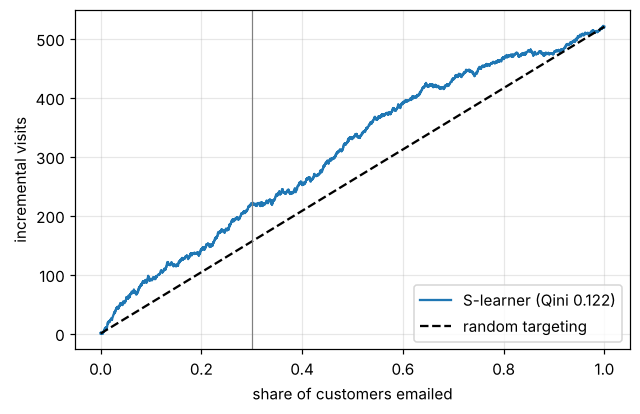

In [5]:
yt, tt = y[test], t[test]
x, q = L.qini_curve(yt, uplift, tt)
plt.figure(figsize=(6.5, 4))
plt.plot(x / len(yt), q, label=f"S-learner (Qini {L.qini(yt, uplift, tt):.3f})")
plt.plot([0, 1], [0, q[-1]], "k--", label="random targeting")
plt.axvline(0.3, color="grey", lw=0.8)
plt.xlabel("share of customers emailed")
plt.ylabel("incremental visits")
plt.legend()
plt.grid(alpha=0.3)

n_k = int(np.ceil(0.3 * len(yt)))
model_visits, random_visits = L.uplift_at_k(yt, uplift, tt, 0.3) * n_k, L.ate(yt, tt) * n_k
print(f"emailing 30% ({n_k:,} customers): {model_visits:.0f} extra visits by uplift vs {random_visits:.0f} at random "
      f"-> {model_visits / random_visits - 1:+.0%}")

## 5. Uplift by decile
Customers are ranked by predicted uplift and cut into tenths. The observed uplift (treated minus control
visit rate inside each tenth) should trend down from left to right. Each tenth holds only about 1,280
customers, so single bars are noisy; the top tenth is what targeting relies on.

top decile observed uplift 11.2% vs 6.1% overall


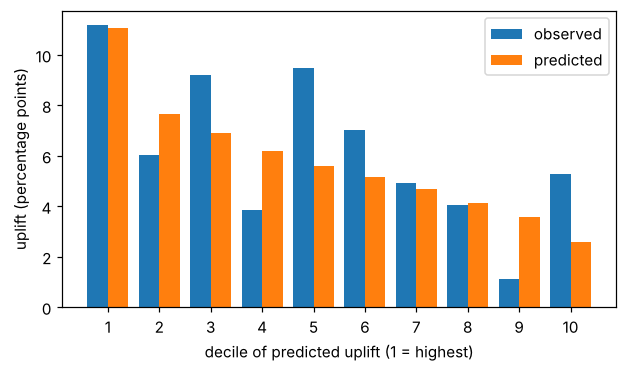

In [6]:
rows = L.deciles(yt, uplift, tt)
d = np.arange(1, 11)
plt.figure(figsize=(6.5, 3.5))
plt.bar(d - 0.2, [r["observed_uplift"] * 100 for r in rows], 0.4, label="observed")
plt.bar(d + 0.2, [r["predicted_uplift"] * 100 for r in rows], 0.4, label="predicted")
plt.xticks(d)
plt.xlabel("decile of predicted uplift (1 = highest)")
plt.ylabel("uplift (percentage points)")
plt.legend()
print(f"top decile observed uplift {rows[0]['observed_uplift']:.1%} vs {L.ate(yt, tt):.1%} overall")

## 6. What drives the uplift? (TreeSHAP)
An XGBoost surrogate copies the model's predicted uplift; its exact TreeSHAP values explain it. R² says
how faithful the surrogate is.

surrogate R^2 on test: 0.992


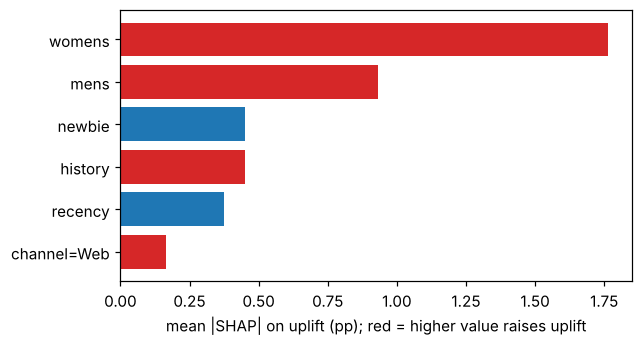

In [7]:
r2, importance, shap = L.explain(Xtr, model.predict(Xtr), Xte, uplift)
print(f"surrogate R^2 on test: {r2:.3f}")
top = importance[:6][::-1]
plt.figure(figsize=(6, 3.2))
plt.barh([i["feature"] for i in top], [i["mean_abs_shap"] * 100 for i in top],
         color=["tab:red" if i["direction"] > 0 else "tab:blue" for i in top])
plt.xlabel("mean |SHAP| on uplift (pp); red = higher value raises uplift")

## 7. Score a few customers
Who would we email? Highest and lowest predicted uplift among the test customers.

In [8]:
scored = df.iloc[test].reset_index(drop=True)[["recency", "history", "mens", "womens", "newbie", "channel"]].copy()
scored["predicted_uplift_pp"] = (uplift * 100).round(2)
scored.sort_values("predicted_uplift_pp", ascending=False).iloc[[0, 1, 2, -3, -2, -1]]

,recency,history,mens,womens,newbie,channel,predicted_uplift_pp
2012,2,296.77,1,1,1,Phone,15.13
5680,1,285.74,1,1,1,Phone,14.95
10045,2,287.04,1,1,1,Phone,14.42
6073,3,964.62,1,0,1,Multichannel,1.27
5623,10,162.04,1,0,0,Phone,1.26
12447,3,635.94,1,0,1,Multichannel,1.16
